In [ ]:
from google.colab import files  # works in Google Colab
uploaded = files.upload()


Saving retail-orders.csv to retail-orders (1).csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("retail-orders.csv")

# Display first five rows
df.head()

,order_id,line_no,ordered_at,customer_id,channel,country,category,units,unit_price_usd,discount_pct,revenue_usd,returned
0,O500860,1,2023-01-01 08:28:00,C5122,android,JP,beauty,4,26.09,0.20,83.49,False
1,O501250,1,2023-01-01 08:56:00,C4066,marketplace,JP,beauty,1,46.37,0.08,42.66,False
2,O502744,1,2023-01-01 15:57:00,C4877,ios,BR,grocery,2,23.67,0.00,47.34,False
3,O503708,1,2023-01-01 16:29:00,C4905,android,JP,apparel,1,35.09,0.00,35.09,False
4,O503708,2,2023-01-01 16:29:00,C4905,android,JP,apparel,2,56.24,0.00,112.48,False


In [ ]:
print("Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe(include="all")

Rows and Columns: (7000, 12)

Column Names:
Index(['order_id', 'line_no', 'ordered_at', 'customer_id', 'channel',
       'country', 'category', 'units', 'unit_price_usd', 'discount_pct',
       'revenue_usd', 'returned'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        7000 non-null   object 
 1   line_no         7000 non-null   int64  
 2   ordered_at      7000 non-null   object 
 3   customer_id     7000 non-null   object 
 4   channel         7000 non-null   object 
 5   country         7000 non-null   object 
 6   category        7000 non-null   object 
 7   units           7000 non-null   int64  
 8   unit_price_usd  7000 non-null   float64
 9   discount_pct    7000 non-null   float64
 10  revenue_usd     7000 non-null   float64
 11  returned        7000 non-null   bool 

,order_id,line_no,ordered_at,customer_id,channel,country,category,units,unit_price_usd,discount_pct,revenue_usd,returned
count,7000,7000.000000,7000,7000,7000,7000,7000,7000.000000,7000.000000,7000.000000,7000.000000,7000
unique,4169,NaN,4159,1649,4,8,6,NaN,NaN,NaN,NaN,2
top,O500859,NaN,2024-11-16 21:48:00,C4845,web,US,apparel,NaN,NaN,NaN,NaN,False
freq,4,NaN,5,19,2734,2655,1696,NaN,NaN,NaN,NaN,6323
mean,NaN,1.584714,NaN,NaN,NaN,NaN,NaN,1.693286,72.662411,0.096569,110.560624,NaN
std,NaN,0.822057,NaN,NaN,NaN,NaN,NaN,1.162131,71.403657,0.119820,152.238442,NaN
min,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,1.000000,6.070000,0.000000,5.320000,NaN
25%,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,1.000000,28.405000,0.000000,33.200000,NaN
50%,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,1.000000,48.860000,0.000000,60.100000,NaN
75%,NaN,2.000000,NaN,NaN,NaN,NaN,NaN,2.000000,81.712500,0.190000,125.300000,NaN


Standardize column names

In [ ]:
# Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns)

Index(['order_id', 'line_no', 'ordered_at', 'customer_id', 'channel',
       'country', 'category', 'units', 'unit_price_usd', 'discount_pct',
       'revenue_usd', 'returned'],
      dtype='object')


In [ ]:
# remove unnecessary spaces from text columns:
text_columns = [
    "order_id",
    "customer_id",
    "channel",
    "country",
    "category"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

In [ ]:
# Standardize text formats
df["channel"] = df["channel"].str.lower()
df["country"] = df["country"].str.upper()
df["category"] = df["category"].str.lower()

In [ ]:
df = pd.read_csv("retail-orders.csv")

print(df["ordered_at"].head(10).to_list())

print("\nOriginal data type:")
print(df["ordered_at"].dtype)

print("\nFirst date value:")
print(repr(df["ordered_at"].iloc[0]))

['2023-01-01 08:28:00', '2023-01-01 08:56:00', '2023-01-01 15:57:00', '2023-01-01 16:29:00', '2023-01-01 16:29:00', '2023-01-01 21:45:00', '2023-01-01 21:45:00', '2023-01-02 08:16:00', '2023-01-02 18:18:00', '2023-01-02 18:24:00']

Original data type:
object

First date value:
'2023-01-01 08:28:00'


In [ ]:
df["ordered_at"] = pd.to_datetime(
    df["ordered_at"],
    format="%Y-%m-%d %H:%M:%S"
)

In [ ]:
print(df["ordered_at"].head())
print(df["ordered_at"].dtype)
print(df["ordered_at"].isna().sum())

0   2023-01-01 08:28:00
1   2023-01-01 08:56:00
2   2023-01-01 15:57:00
3   2023-01-01 16:29:00
4   2023-01-01 16:29:00
Name: ordered_at, dtype: datetime64[ns]
datetime64[ns]
0


In [ ]:
print("Invalid Dates:", df["ordered_at"].isna().sum())

Invalid Dates: 0


In [ ]:
#Check and identify duplicate records

In [ ]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [ ]:
# check duplicate order-line combinations.
duplicate_order_lines = df[
    df.duplicated(
        subset=["order_id", "line_no"],
        keep=False
    )
]

print("Duplicate Order-Line Records:")
display(duplicate_order_lines)

Duplicate Order-Line Records:


,order_id,line_no,ordered_at,customer_id,channel,country,category,units,unit_price_usd,discount_pct,revenue_usd,returned


In [ ]:
#Check missing values
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

print(missing_values)

                Missing_Count  Missing_Percentage
order_id                    0                 0.0
line_no                     0                 0.0
ordered_at                  0                 0.0
customer_id                 0                 0.0
channel                     0                 0.0
country                     0                 0.0
category                    0                 0.0
units                       0                 0.0
unit_price_usd              0                 0.0
discount_pct                0                 0.0
revenue_usd                 0                 0.0
returned                    0                 0.0


In [ ]:
# Handle discount only when the business confirms
# that missing discount means no discount.

df["discount_pct"] = df["discount_pct"].fillna(0)

In [ ]:
#For the remaining columns, inspect missing records:
df[df.isnull().any(axis=1)]

,order_id,line_no,ordered_at,customer_id,channel,country,category,units,unit_price_usd,discount_pct,revenue_usd,returned


In [ ]:
#Validate quantity and price fields
df["units"] = pd.to_numeric(
    df["units"],
    errors="coerce"
)

invalid_quantity = df[
    (df["units"].isna()) |
    (df["units"] <= 0) |
    (df["units"] % 1 != 0)
]

print("Invalid Quantity Records:")
display(invalid_quantity)

Invalid Quantity Records:


,order_id,line_no,ordered_at,customer_id,channel,country,category,units,unit_price_usd,discount_pct,revenue_usd,returned


In [ ]:
#Validate unit price
df["unit_price_usd"] = pd.to_numeric(
    df["unit_price_usd"],
    errors="coerce"
)

invalid_price = df[
    (df["unit_price_usd"].isna()) |
    (df["unit_price_usd"] < 0)
]

print("Invalid Price Records:")
display(invalid_price)

Invalid Price Records:


,order_id,line_no,ordered_at,customer_id,channel,country,category,units,unit_price_usd,discount_pct,revenue_usd,returned


In [ ]:
#validate discount percentage
df["discount_pct"] = pd.to_numeric(
    df["discount_pct"],
    errors="coerce"
)

invalid_discount = df[
    (df["discount_pct"].isna()) |
    (df["discount_pct"] < 0) |
    (df["discount_pct"] > 1)
]

print("Invalid Discount Records:")
display(invalid_discount)

Invalid Discount Records:


,order_id,line_no,ordered_at,customer_id,channel,country,category,units,unit_price_usd,discount_pct,revenue_usd,returned


In [ ]:
#Calculate and validate revenue
#Revenue = Units × Unit Price × (1 − Discount Percentage)
df["calculated_revenue"] = (
    df["units"] *
    df["unit_price_usd"] *
    (1 - df["discount_pct"])
).round(2)

In [ ]:
#Compare original revenue with calculated revenue:
df["revenue_usd"] = pd.to_numeric(
    df["revenue_usd"],
    errors="coerce"
)

df["revenue_difference"] = (
    df["revenue_usd"] -
    df["calculated_revenue"]
).round(2)

revenue_mismatch = df[
    df["revenue_difference"].abs() > 0.01
]

print("Revenue Mismatches:")
display(revenue_mismatch[
    [
        "order_id",
        "units",
        "unit_price_usd",
        "discount_pct",
        "revenue_usd",
        "calculated_revenue",
        "revenue_difference"
    ]
])

Revenue Mismatches:


,order_id,units,unit_price_usd,discount_pct,revenue_usd,calculated_revenue,revenue_difference


In [ ]:
#Create a corrected revenue column:
df["revenue_usd"] = df["calculated_revenue"]

In [ ]:
#Create additional date columns
df["year"] = df["ordered_at"].dt.year

df["month"] = df["ordered_at"].dt.month

df["month_name"] = df["ordered_at"].dt.month_name()

df["year_month"] = df["ordered_at"].dt.to_period("M").astype(str)

print(df.head())

  order_id  line_no          ordered_at customer_id      channel country  \
0  O500860        1 2023-01-01 08:28:00       C5122      android      JP   
1  O501250        1 2023-01-01 08:56:00       C4066  marketplace      JP   
2  O502744        1 2023-01-01 15:57:00       C4877          ios      BR   
3  O503708        1 2023-01-01 16:29:00       C4905      android      JP   
4  O503708        2 2023-01-01 16:29:00       C4905      android      JP   

  category  units  unit_price_usd  discount_pct  revenue_usd  returned  \
0   beauty      4           26.09          0.20        83.49     False   
1   beauty      1           46.37          0.08        42.66     False   
2  grocery      2           23.67          0.00        47.34     False   
3  apparel      1           35.09          0.00        35.09     False   
4  apparel      2           56.24          0.00       112.48     False   

   calculated_revenue  revenue_difference  year  month month_name year_month  
0               83.

In [ ]:
#Sales analysis by month
monthly_sales = (
    df.groupby("year_month")["revenue_usd"]
    .sum()
    .reset_index()
)

monthly_sales.columns = [
    "Month",
    "Total_Revenue"
]

print(monthly_sales)

      Month  Total_Revenue
0   2023-01       25361.31
1   2023-02       31323.74
2   2023-03       35285.03
3   2023-04       32872.45
4   2023-05       32646.27
5   2023-06       31248.74
6   2023-07       35500.83
7   2023-08       35250.50
8   2023-09       27253.08
9   2023-10       36738.79
10  2023-11       31031.26
11  2023-12       48202.45
12  2024-01       18567.30
13  2024-02       29705.66
14  2024-03       29452.32
15  2024-04       33869.10
16  2024-05       32766.62
17  2024-06       28722.24
18  2024-07       32398.81
19  2024-08       30813.11
20  2024-09       25098.87
21  2024-10       27431.94
22  2024-11       38408.19
23  2024-12       43975.51


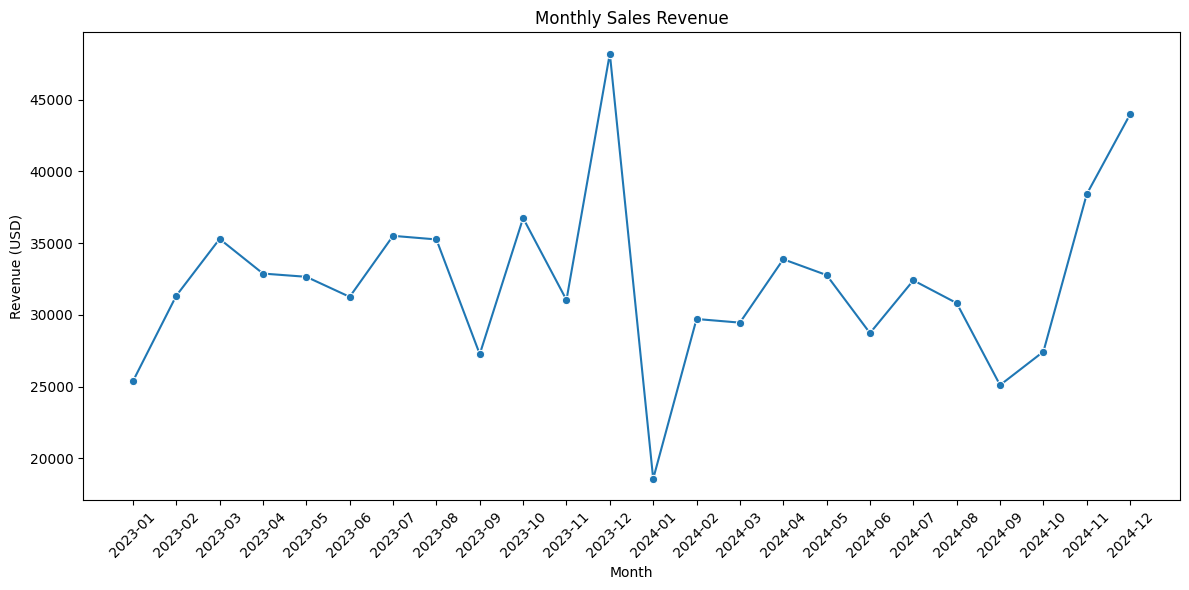

In [ ]:
#Visualize monthly sales:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Total_Revenue",
    marker="o"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
#Sales analysis by product category
category_sales = (
    df.groupby("category")["revenue_usd"]
    .sum()
    .reset_index()
    .sort_values(
        by="revenue_usd",
        ascending=False
    )
)

print(category_sales)

      category  revenue_usd
2  electronics    326203.98
4         home    152269.05
0      apparel    126480.27
5       sports     81482.42
1       beauty     50794.71
3      grocery     36693.69


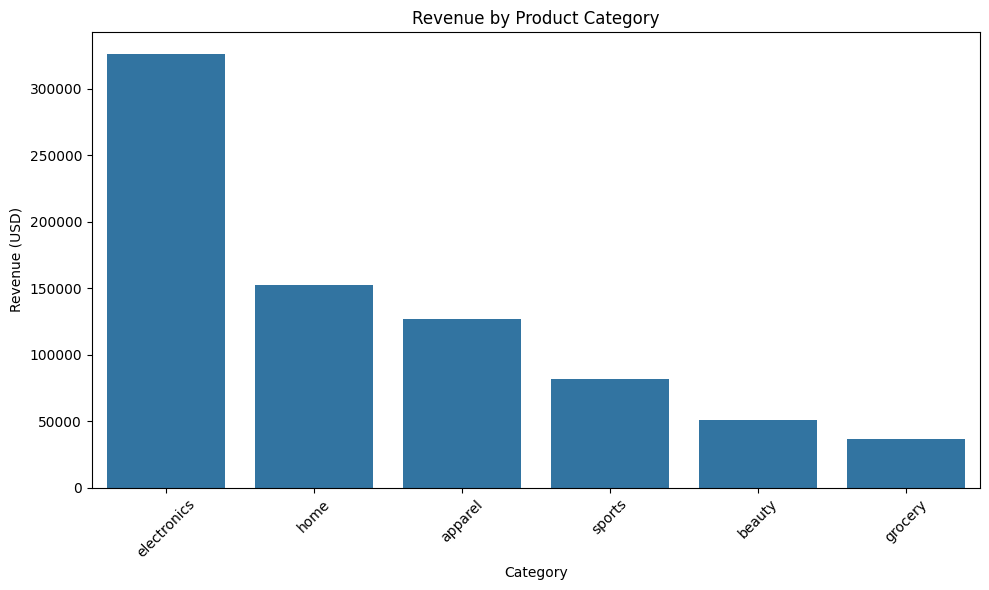

In [ ]:
#Create a bar chart:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_sales,
    x="category",
    y="revenue_usd"
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue (USD)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
#Sales analysis by country
country_sales = (
    df.groupby("country")["revenue_usd"]
    .sum()
    .reset_index()
    .sort_values(
        by="revenue_usd",
        ascending=False
    )
)

print(country_sales)

  country  revenue_usd
7      US    290129.13
5      GB     97784.50
3      DE     81252.23
2      CA     80888.89
6      JP     70121.87
4      FR     59004.80
0      AU     55530.78
1      BR     39211.92


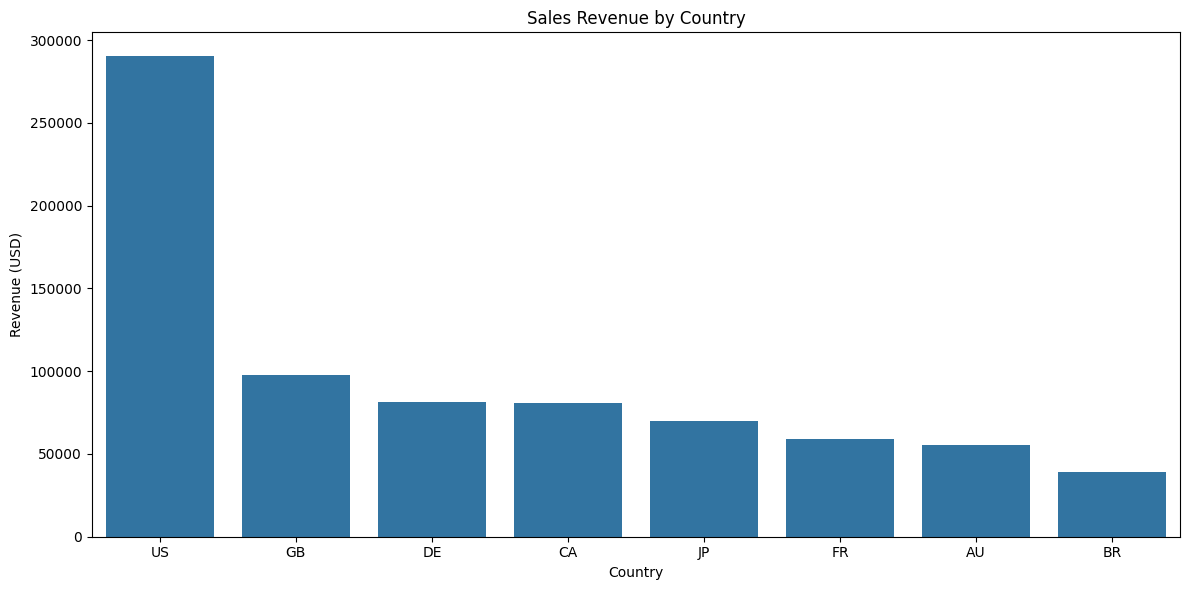

In [ ]:
#Visualize:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=country_sales,
    x="country",
    y="revenue_usd"
)

plt.title("Sales Revenue by Country")
plt.xlabel("Country")
plt.ylabel("Revenue (USD)")

plt.tight_layout()
plt.show()

In [ ]:
#Sales analysis by sales channel
channel_sales = (
    df.groupby("channel")["revenue_usd"]
    .sum()
    .reset_index()
    .sort_values(
        by="revenue_usd",
        ascending=False
    )
)

print(channel_sales)

       channel  revenue_usd
3          web    304583.23
1          ios    201322.55
0      android    158567.20
2  marketplace    109451.14


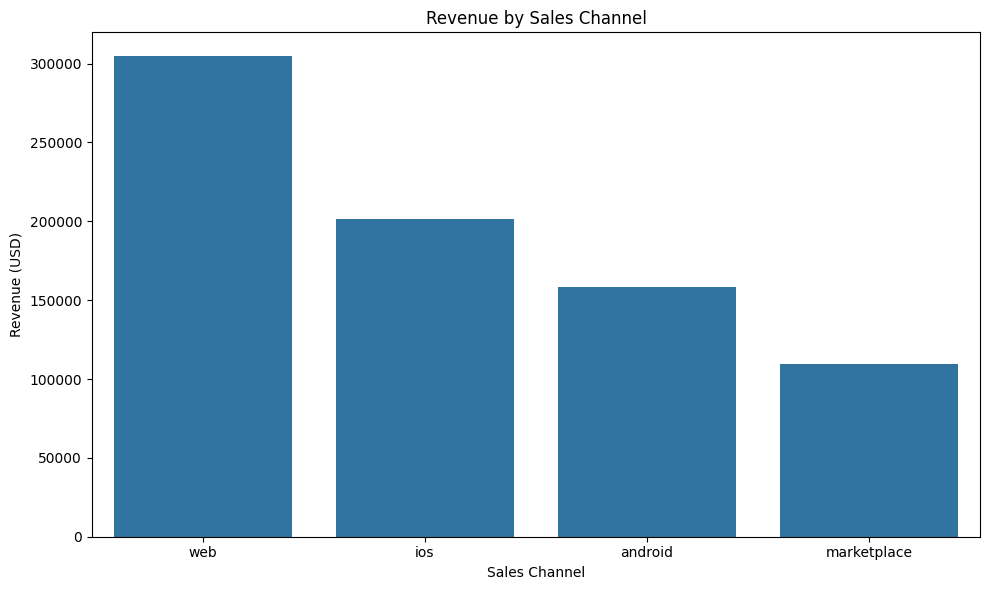

In [ ]:
#Visualize:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=channel_sales,
    x="channel",
    y="revenue_usd"
)

plt.title("Revenue by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Revenue (USD)")

plt.tight_layout()
plt.show()

In [ ]:
#Return analysis
return_analysis = (
    df.groupby("returned")
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Units=("units", "sum"),
        Total_Revenue=("revenue_usd", "sum")
    )
    .reset_index()
)

print(return_analysis)

   returned  Total_Orders  Total_Units  Total_Revenue
0     False          3943        10648      693244.95
1      True           647         1205       80679.17


In [ ]:
#Check the percentage of returned order lines:
return_percentage = (
    df["returned"].eq(True).mean() * 100
)

print(
    "Returned Line Percentage:",
    round(return_percentage, 2),
    "%"
)

Returned Line Percentage: 9.67 %


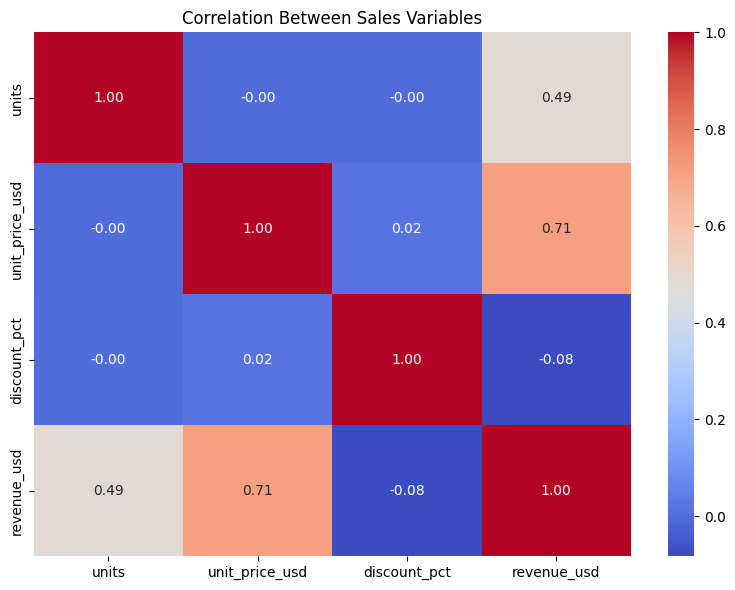

In [ ]:
#Create a correlation heatmap
numeric_columns = [
    "units",
    "unit_price_usd",
    "discount_pct",
    "revenue_usd"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Sales Variables")

plt.tight_layout()
plt.show()

In [ ]:
#Final data quality report
quality_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Duplicate Order-Line Records",
        "Missing Values",
        "Invalid Dates",
        "Invalid Quantities",
        "Invalid Prices",
        "Invalid Discounts",
        "Revenue Mismatches"
    ],

    "Count": [
        len(df),
        len(duplicate_order_lines),
        df.isnull().sum().sum(),
        df["ordered_at"].isna().sum(),
        len(invalid_quantity),
        len(invalid_price),
        len(invalid_discount),
        len(revenue_mismatch)
    ]
})

display(quality_report)

,Metric,Count
0,Total Records,7000
1,Duplicate Order-Line Records,0
2,Missing Values,0
3,Invalid Dates,0
4,Invalid Quantities,0
5,Invalid Prices,0
6,Invalid Discounts,0
7,Revenue Mismatches,0


In [ ]:
#Export our cleaned dataset
# Export cleaned dataset
df.to_csv(
    "cleaned_ecommerce_sales.csv",
    index=False
)

df.to_excel(
    "cleaned_ecommerce_sales.xlsx",
    index=False
)

# Export quality report
quality_report.to_excel(
    "data_quality_report.xlsx",
    index=False
)

print("Files exported successfully!")

Files exported successfully!


In [ ]:
from google.colab import files

files.download("cleaned_ecommerce_sales.csv")
files.download("cleaned_ecommerce_sales.xlsx")
files.download("data_quality_report.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>